# EMNIST: ten digit-like letter classes

Inspect the exact `emnist` dataset exposed by `dataset_utils` for a future MNIST → EMNIST LoRA experiment. The selected letters are **B, G, I, L, O, Q, S, T, Y, Z**. Their loops and strokes often resemble digits, but this is a visual heuristic, not a measured similarity ranking. The [official EMNIST Letters split](https://www.nist.gov/itl/products-and-services/emnist-dataset) merges uppercase and lowercase handwriting, so examples within a class can look quite different.

The loader keeps only these ten classes, remaps their labels to `0–9` in the order above, and transposes the stored image axes to obtain upright, unmirrored characters. It uses the same `1 × 28 × 28`, grayscale `[0, 1]` preprocessing as MNIST. The labels identify letters; they do not assign digit identities.

On first use, torchvision downloads the full official EMNIST archive into `paths.dataset_dir`. Subsequent runs reuse the local files. Run the cells from the repository root or the `notebooks` directory using the project's Python environment.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

repo_root = Path.cwd().resolve()
if not (repo_root / "pyproject.toml").exists():
    repo_root = repo_root.parent
if not (repo_root / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(repo_root / "src"))

from domain_knowledge_analysis import utils
from domain_knowledge_analysis.utils.dataset_utils import (
    EMNIST_LETTERS,
    create_train_validation_datasets,
)

## Settings and dataset loading

`USE_TEST_SPLIT` changes which pool supplies the sample galleries. The count plot always includes the actual training, validation, and held-out test splits. The selected subset has 48,000 training-pool images and 8,000 test images; with `train_split=0.8`, the training and validation sets contain 38,400 and 9,600 examples. Validation is the repository's existing seeded random split, so its class counts can vary slightly.

In [2]:
USE_TEST_SPLIT = False
EXAMPLES_PER_CLASS = 6
SAMPLE_SEED = 123

config = utils.load_config(repo_root / "config" / "vae_mnist.yaml")
config["dataset"]["name"] = "emnist"
train_dataset, validation_dataset = create_train_validation_datasets(config, "emnist")
training_pool = train_dataset.dataset
test_dataset = utils.create_dataset(config, "emnist", train=False)
dataset = test_dataset if USE_TEST_SPLIT else training_pool
split_name = "test" if USE_TEST_SPLIT else "training pool"
classes = list(EMNIST_LETTERS)

assert training_pool.classes == test_dataset.classes == classes
assert len(training_pool) == 48_000 and len(test_dataset) == 8_000
assert torch.equal(torch.bincount(training_pool.targets), torch.full((10,), 4_800))
assert torch.equal(torch.bincount(test_dataset.targets), torch.full((10,), 800))
assert set(train_dataset.indices).isdisjoint(validation_dataset.indices)

image, label = dataset[0]
assert tuple(image.shape) == tuple(config["dataset"]["shape"]) == (1, 28, 28)
assert image.dtype == torch.float32 and 0 <= image.min() <= image.max() <= 1
print(f"Training pool: {len(training_pool):,}; training: {len(train_dataset):,}; "
      f"validation: {len(validation_dataset):,}; test: {len(test_dataset):,}")
print(f"Gallery split: {split_name}; tensor: {tuple(image.shape)}; dtype: {image.dtype}")
print(f"Label mapping: {dict(enumerate(classes))}")

Training pool: 48,000; training: 38,400; validation: 9,600; test: 8,000
Gallery split: training pool; tensor: (1, 28, 28); dtype: torch.float32
Label mapping: {0: 'B', 1: 'G', 2: 'I', 3: 'L', 4: 'O', 5: 'Q', 6: 'S', 7: 'T', 8: 'Y', 9: 'Z'}


## Why these letters?

The digit column below gives an illustrative visual analogy, not a training label or a claim that every sample has that shape. There is no requirement to cover every MNIST digit once: I and L both offer simple strokes resembling 1. Lowercase b can resemble 6, while capital B resembles 8; uppercase/lowercase variation is visible in the gallery.

In [3]:
# Illustrative analogies used only for display; EMNIST labels remain alphabetical.
comparison_digits = {"B": 8, "G": 6, "I": 1, "L": 1, "O": 0,
                     "Q": 9, "S": 5, "T": 7, "Y": 4, "Z": 2}
rows = ["| Class label | Letter (both cases) | Original EMNIST label | Digit analogy |",
        "| --- | --- | --- | --- |"]
for label, letter in enumerate(classes):
    original_label = ord(letter) - ord("A") + 1
    rows.append(f"| {label} | {letter} / {letter.lower()} | {original_label} | {comparison_digits[letter]} |")
display(Markdown("\n".join(rows)))

| Class label | Letter (both cases) | Original EMNIST label | Digit analogy |
| --- | --- | --- | --- |
| 0 | B / b | 2 | 8 |
| 1 | G / g | 7 | 6 |
| 2 | I / i | 9 | 1 |
| 3 | L / l | 12 | 1 |
| 4 | O / o | 15 | 0 |
| 5 | Q / q | 17 | 9 |
| 6 | S / s | 19 | 5 |
| 7 | T / t | 20 | 7 |
| 8 | Y / y | 25 | 4 |
| 9 | Z / z | 26 | 2 |

## Class counts in the actual splits

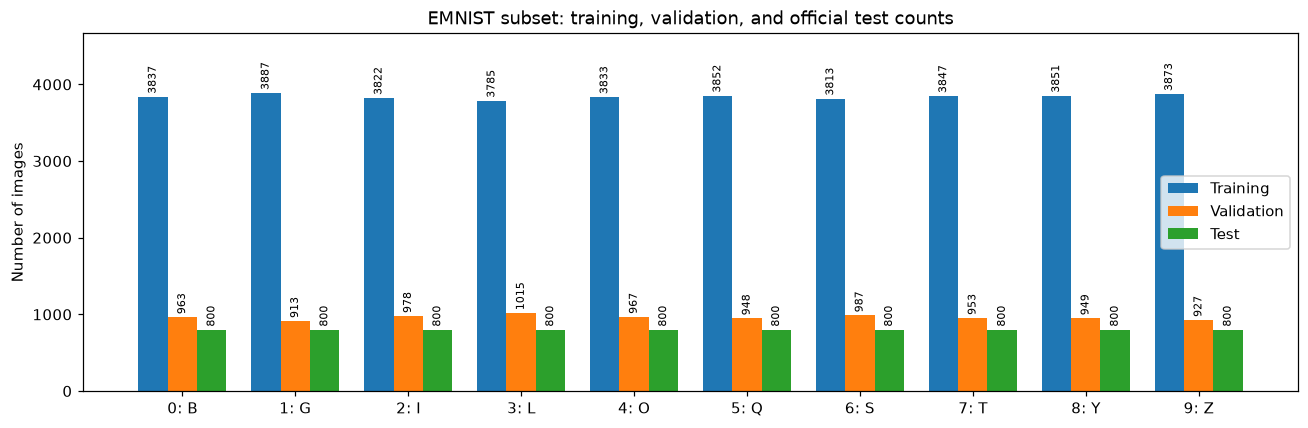

In [4]:
counts = {
    "Training": torch.bincount(training_pool.targets[train_dataset.indices], minlength=10),
    "Validation": torch.bincount(training_pool.targets[validation_dataset.indices], minlength=10),
    "Test": torch.bincount(test_dataset.targets, minlength=10),
}
positions = torch.arange(len(classes))
fig, ax = plt.subplots(figsize=(12, 4))
for offset, (name, values) in enumerate(counts.items()):
    bars = ax.bar(positions + (offset - 1) * 0.26, values, width=0.26, label=name)
    ax.bar_label(bars, fontsize=7, padding=2, rotation=90)
ax.set_xticks(positions, [f"{label}: {letter}" for label, letter in enumerate(classes)])
ax.set_ylabel("Number of images")
ax.set_ylim(0, max(counts["Training"]).item() * 1.2)
ax.set_title("EMNIST subset: training, validation, and official test counts")
ax.legend()
fig.tight_layout()
plt.show()

## Multiple handwriting samples per letter

The samples are reproducible from `SAMPLE_SEED`. These tensors come directly from `utils.create_dataset`; the plotting code applies no extra rotation, reflection, scaling, or thresholding. Change the seed to inspect more handwriting styles.

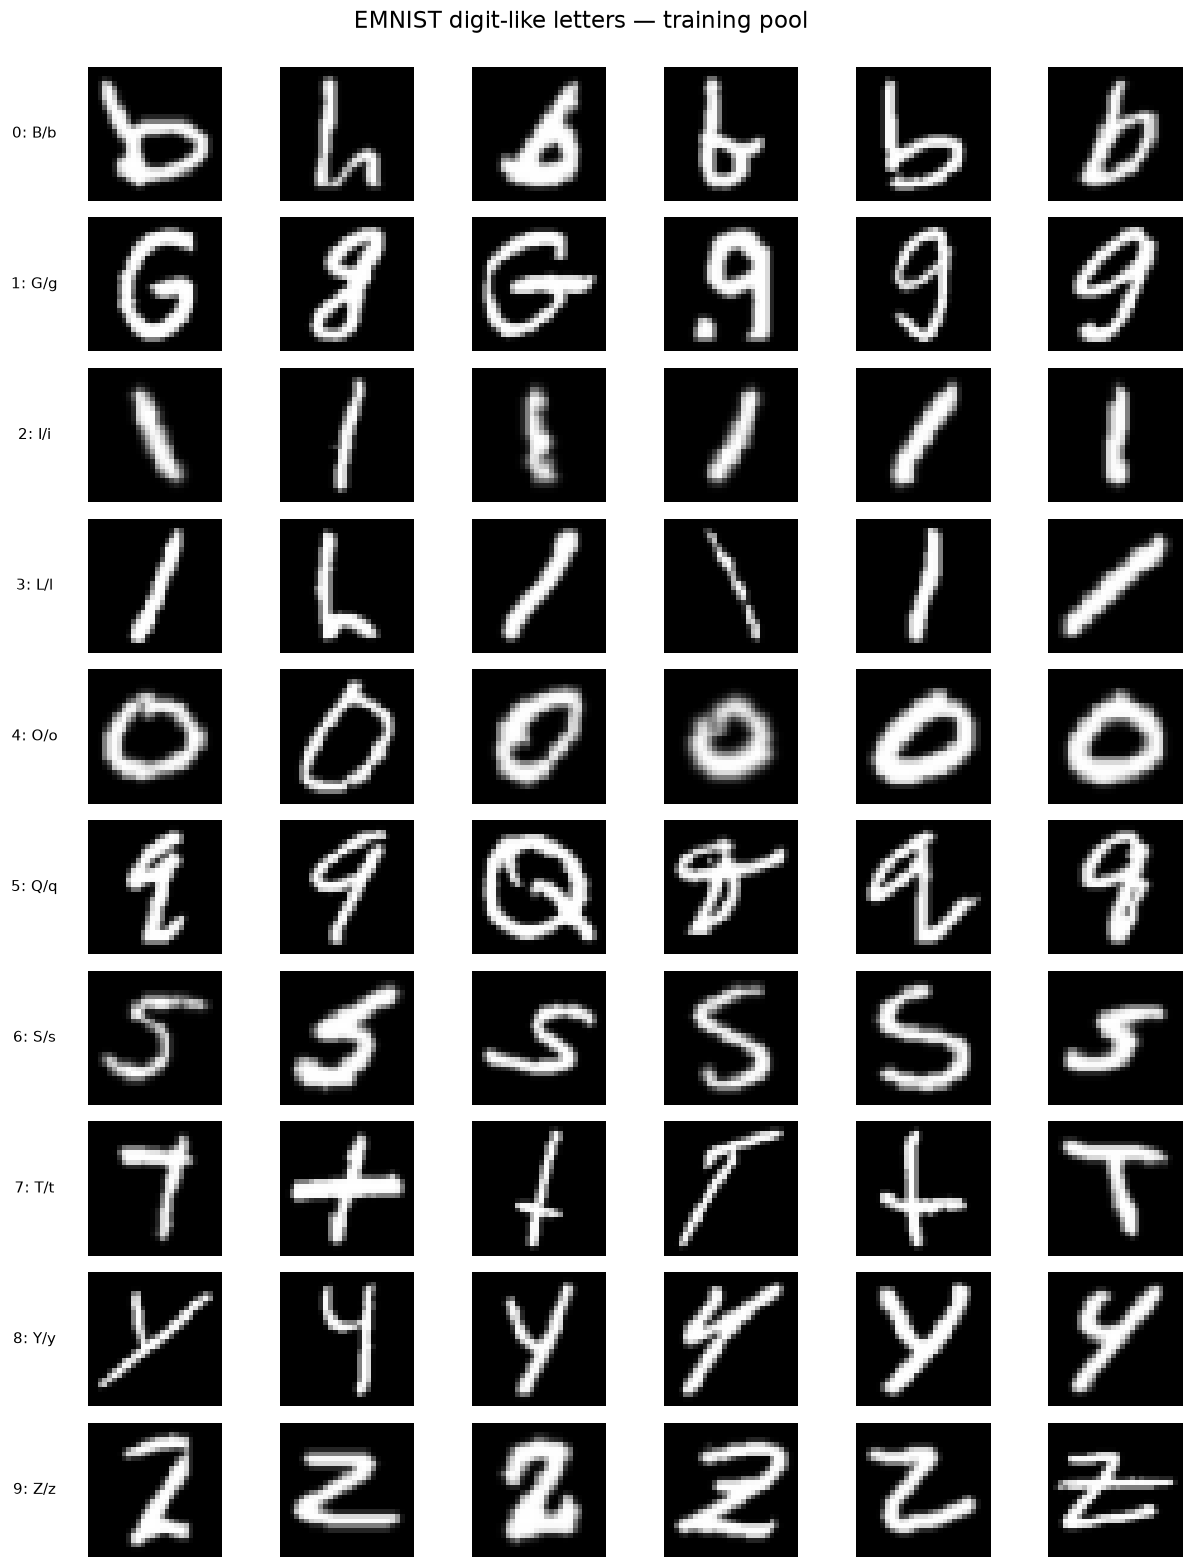

In [5]:
def select_class_samples(targets, class_label, count, generator):
    candidates = torch.where(targets == class_label)[0]
    if count < 1 or count > len(candidates):
        raise ValueError(f"Request between 1 and {len(candidates)} samples for class {class_label}.")
    return candidates[torch.randperm(len(candidates), generator=generator)[:count]].tolist()


def show_image(axis, image):
    axis.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)


generator = torch.Generator().manual_seed(SAMPLE_SEED)
fig, axes = plt.subplots(len(classes), EXAMPLES_PER_CLASS,
                         figsize=(2 * EXAMPLES_PER_CLASS, 1.45 * len(classes)), squeeze=False)
for class_label, letter in enumerate(classes):
    indices = select_class_samples(dataset.targets, class_label, EXAMPLES_PER_CLASS, generator)
    for column, index in enumerate(indices):
        image, observed_label = dataset[index]
        assert observed_label == class_label
        show_image(axes[class_label, column], image)
    axes[class_label, 0].set_ylabel(f"{class_label}: {letter}/{letter.lower()}",
                                  rotation=0, labelpad=35, va="center")
fig.suptitle(f"EMNIST digit-like letters — {split_name}", fontsize=15)
fig.tight_layout(rect=(0.04, 0, 1, 0.98))
plt.show()

## MNIST and EMNIST side by side

Each row compares two MNIST digit examples with two examples of the analogous letter class. Both datasets use the same grayscale scale and preprocessing. The digit analogies help assess the domain shift; they do not change either dataset's labels or filter individual handwriting samples.

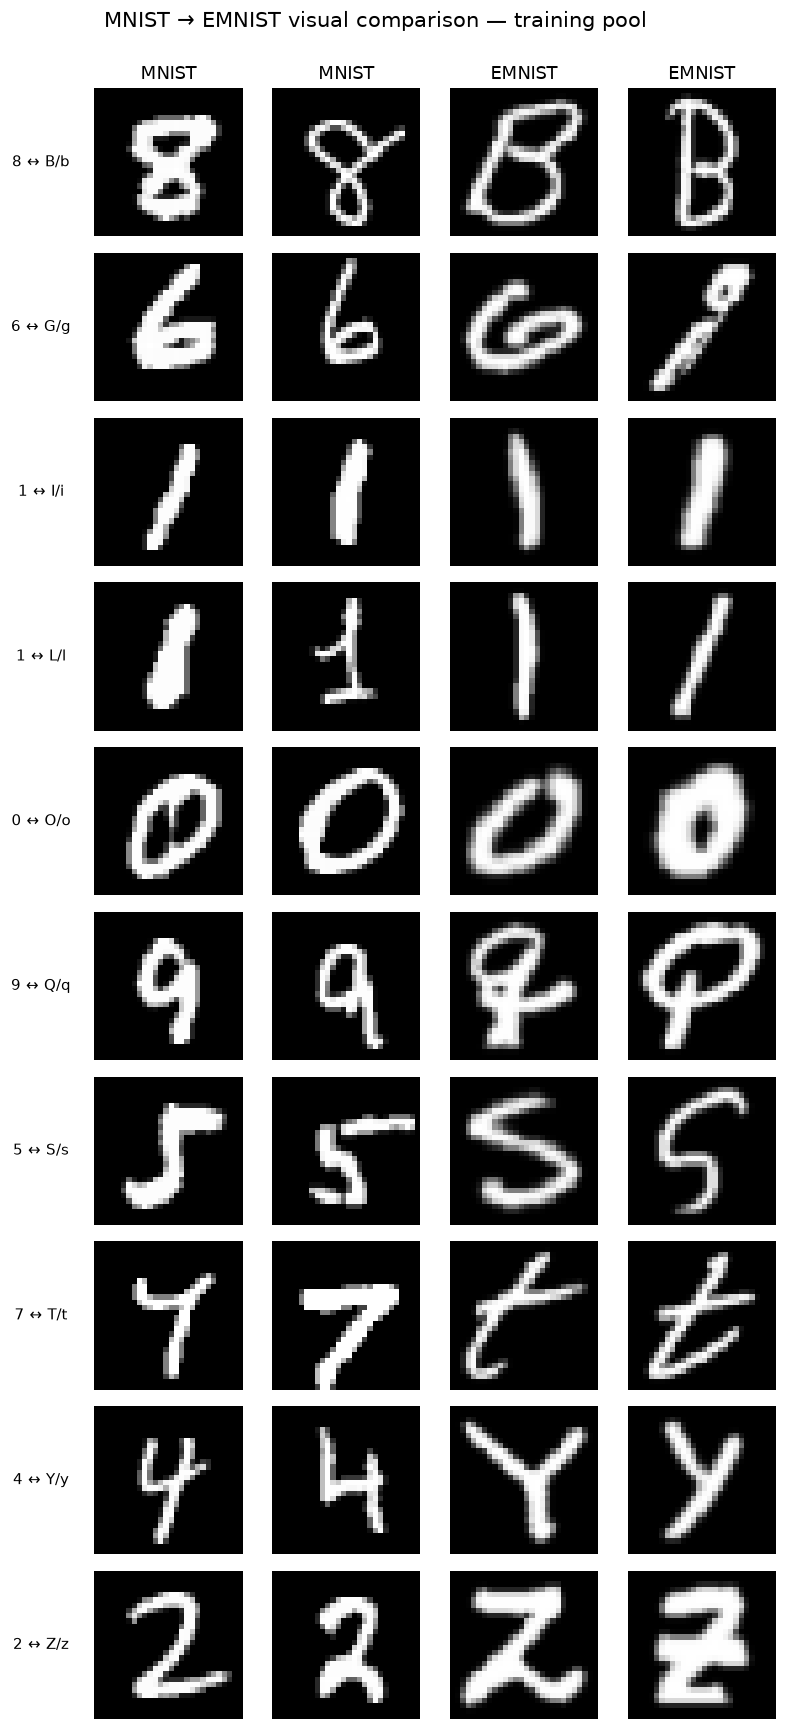

In [6]:
mnist = utils.create_dataset(config, "mnist", train=not USE_TEST_SPLIT)
generator = torch.Generator().manual_seed(SAMPLE_SEED)
fig, axes = plt.subplots(len(classes), 4, figsize=(8, 1.6 * len(classes)), squeeze=False)
for class_label, letter in enumerate(classes):
    digit = comparison_digits[letter]
    digit_indices = select_class_samples(mnist.targets, digit, 2, generator)
    letter_indices = select_class_samples(dataset.targets, class_label, 2, generator)
    for column, index in enumerate(digit_indices):
        show_image(axes[class_label, column], mnist[index][0])
    for column, index in enumerate(letter_indices, start=2):
        show_image(axes[class_label, column], dataset[index][0])
    axes[class_label, 0].set_ylabel(f"{digit} ↔ {letter}/{letter.lower()}", rotation=0, labelpad=35, va="center")
for axis, title in zip(axes[0], ["MNIST", "MNIST", "EMNIST", "EMNIST"]):
    axis.set_title(title)
fig.suptitle(f"MNIST → EMNIST visual comparison — {split_name}", fontsize=14)
fig.tight_layout(rect=(0.06, 0, 1, 0.98))
plt.show()

## Using the subset

```python
emnist_training_pool = utils.create_dataset(config, "emnist", train=True)
emnist_test = utils.create_dataset(config, "emnist", train=False)
# config["dataset"]["name"] is already "emnist" in this notebook.
train_loader, validation_loader = utils.create_training_dataloaders(config)
test_loader = utils.create_testing_dataloaders(config)
```

The same name works with the existing scoring and calibration loaders. The configuration continues to control the seed, train/validation fraction, batch size, and likelihood preprocessing. This notebook uses the Bernoulli preprocessing in `vae_mnist.yaml`. Continuous Bernoulli configurations also apply the repository's usual deterministic uniform dequantization.

For MNIST → EMNIST LoRA, keep the top-level `dataset.name: mnist` as the source and choose the target through the existing LoRA block:

```yaml
lora:
  transformed_dataset:
    name: emnist
    train_split: 0.8
    shape: [1, 28, 28]
```

See `config/lora_vae_mnist_emnist.yaml` for the complete configuration. A registered dataset name loads that target directly, including its official test set; leftover `type` and `intensity` fields are ignored. Source evaluation and regularizer anchors continue to use MNIST. To use rotated MNIST, keep `name: rotated_mnist`, `type: rotation`, and the desired `intensity` in the same block. This notebook does not launch training.